In [18]:
import os
import pathlib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [19]:
# Define paths and parameters from the prompt
BASE_DIR = r'C:\Users\hemanth\Desktop\3D_CNN'
IMAGE_WIDTH = 128
IMAGE_HEIGHT = 128
IMAGE_CHANNELS = 3  # Assuming RGB images, adjust if grayscale
BATCH_SIZE = 64
VALIDATION_SPLIT = 0.15
EPOCHS = 100  # Set a reasonable number as 'infinite' isn't practical
LEARNING_RATE = 0.001

In [20]:
# Data loading and augmentation
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=VALIDATION_SPLIT
)

In [21]:
# Create data generators for training and validation
train_generator = datagen.flow_from_directory(
    BASE_DIR,
    target_size=(IMAGE_HEIGHT, IMAGE_WIDTH),
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    shuffle=True,
    subset='training'
)

Found 16386 images belonging to 2 classes.


In [22]:
validation_generator = datagen.flow_from_directory(
    BASE_DIR,
    target_size=(IMAGE_HEIGHT, IMAGE_WIDTH),
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    shuffle=False,
    subset='validation'
)

Found 2890 images belonging to 2 classes.


In [23]:
# Check the number of classes and class names
num_classes = train_generator.num_classes
class_names = list(train_generator.class_indices.keys())
print(f"Found {train_generator.samples} training images belonging to {num_classes} classes: {class_names}")
print(f"Found {validation_generator.samples} validation images belonging to {num_classes} classes: {class_names}")

Found 16386 training images belonging to 2 classes: ['Control', 'Diseased']
Found 2890 validation images belonging to 2 classes: ['Control', 'Diseased']


In [24]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import LeakyReLU, Activation

def create_2d_cnn_model_with_alternates(input_shape, num_classes, learning_rate):
    """
    Creates and compiles a 2D CNN model replacing ReLU with alternatives.
    """
    model = keras.Sequential([
        # First Convolutional Block with Leaky ReLU
        layers.Conv2D(32, (3, 3), input_shape=input_shape),
        LeakyReLU(alpha=0.1), # Replaces 'relu' activation
        layers.MaxPooling2D((2, 2)),
        
        # Second Convolutional Block with Swish
        layers.Conv2D(64, (3, 3), activation='swish'), # Replaces 'relu' activation
        layers.MaxPooling2D((2, 2)),
        
        # Third Convolutional Block with Leaky ReLU
        layers.Conv2D(128, (3, 3)),
        LeakyReLU(alpha=0.1),
        layers.MaxPooling2D((2, 2)),
        
        # Flatten and Dense Layers with Swish
        layers.Flatten(),
        layers.Dense(128, activation='swish'), # Replaces 'relu' activation
        layers.Dropout(0.9),
        layers.Dense(num_classes, activation='softmax')
    ])
    
    # Compile the model
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer,
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    
    return model

In [25]:
# Create the model
input_shape = (IMAGE_HEIGHT, IMAGE_WIDTH, IMAGE_CHANNELS)
model = create_2d_cnn_model_with_alternates(input_shape, num_classes, LEARNING_RATE)
model.summary()

C:\Users\hemanth\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
C:\Users\hemanth\anaconda3\Lib\site-packages\keras\src\layers\activations\leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_2 (LeakyReLU)            │ (None, 126, 126, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_3 (LeakyReLU)            │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 2)                   │             258 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,304,898 (12.61 MB)

 Trainable params: 3,304,898 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    # Monitors validation accuracy
    monitor='val_accuracy',
    # Stops training if validation accuracy doesn't improve for 3 epochs
    patience=2, 
    verbose=1,
    # Restores the best-performing weights
    restore_best_weights=True
)

# Modified learning rate parameter in the Adam optimizer
optimizer = Adam(learning_rate=0.001)

# Modified ReduceLROnPlateau callback
reduce_lr = ReduceLROnPlateau(
    monitor='val_accuracy',
    factor=0.1,
    patience=2,
    min_lr=0.00001,  # Lowered the minimum learning rate
    verbose=1
)

In [27]:
# Train the model
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    callbacks=[early_stopping, reduce_lr]
)

C:\Users\hemanth\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/100
257/257 ━━━━━━━━━━━━━━━━━━━━ 207s 789ms/step - accuracy: 0.7345 - loss: 0.5334 - val_accuracy: 0.8965 - val_loss: 0.3170 - learning_rate: 0.0010
Epoch 2/100
257/257 ━━━━━━━━━━━━━━━━━━━━ 189s 735ms/step - accuracy: 0.9629 - loss: 0.1132 - val_accuracy: 0.9682 - val_loss: 0.0861 - learning_rate: 0.0010
Epoch 3/100
257/257 ━━━━━━━━━━━━━━━━━━━━ 178s 693ms/step - accuracy: 0.9775 - loss: 0.0649 - val_accuracy: 0.9792 - val_loss: 0.0630 - learning_rate: 0.0010
Epoch 4/100
257/257 ━━━━━━━━━━━━━━━━━━━━ 173s 674ms/step - accuracy: 0.9881 - loss: 0.0342 - val_accuracy: 0.9879 - val_loss: 0.0396 - learning_rate: 0.0010
Epoch 5/100
257/257 ━━━━━━━━━━━━━━━━━━━━ 176s 683ms/step - accuracy: 0.9909 - loss: 0.0286 - val_accuracy: 0.9879 - val_loss: 0.0354 - learning_rate: 0.0010
Epoch 6/100
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 916ms/step - accuracy: 0.9921 - loss: 0.0240  
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.
257/257 ━━━━━━━━━━━━━━━━━━━━ 253s 985ms/step - 

In [28]:
history.history

{'accuracy': [0.8473086953163147,
  0.96722811460495,
  0.9798608422279358,
  0.9898083806037903,
  0.9884657859802246,
  0.9924325346946716],
 'loss': [0.3362594544887543,
  0.09708455204963684,
  0.0594748817384243,
  0.02996465004980564,
  0.03304000571370125,
  0.022897791117429733],
 'val_accuracy': [0.8965398073196411,
  0.9681661128997803,
  0.979238748550415,
  0.987889289855957,
  0.987889289855957,
  0.9830449819564819],
 'val_loss': [0.31697821617126465,
  0.08607424050569534,
  0.06300440430641174,
  0.03957928344607353,
  0.03538023680448532,
  0.05700656771659851],
 'learning_rate': [0.0010000000474974513,
  0.0010000000474974513,
  0.0010000000474974513,
  0.0010000000474974513,
  0.0010000000474974513,
  0.0010000000474974513]}

In [29]:
# Evaluate the model
loss, accuracy = model.evaluate(validation_generator)
print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")

46/46 ━━━━━━━━━━━━━━━━━━━━ 17s 361ms/step - accuracy: 0.9825 - loss: 0.0664    
Validation Loss: 0.0470
Validation Accuracy: 0.9862


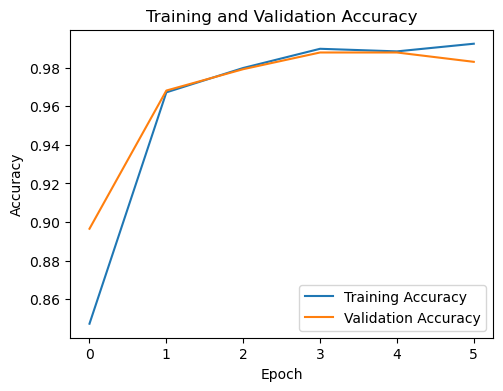

In [30]:
# Plot training and validation accuracy and loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

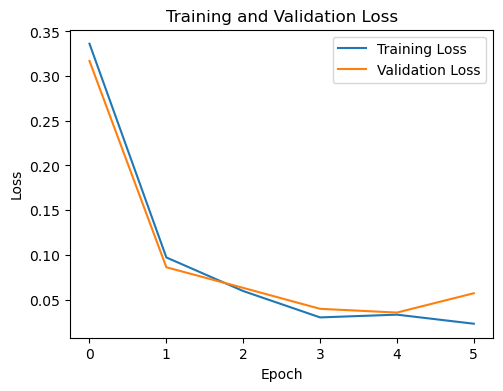

In [31]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [32]:
# Generate and plot confusion matrix
validation_generator.reset()
y_pred = model.predict(validation_generator)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = validation_generator.classes

46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 314ms/step


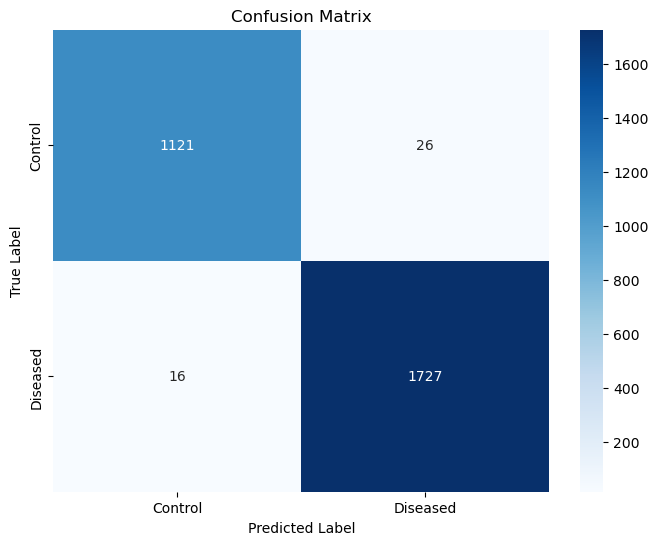

In [33]:
cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [34]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Get the true labels and predicted probabilities from the validation generator
validation_generator.reset()
y_true = validation_generator.classes
y_pred_proba = model.predict(validation_generator)
y_pred_classes = np.argmax(y_pred_proba, axis=1)

# Ensure the labels are correct for the binary case (if applicable)
# For a binary classification problem (e.g., control vs. diseased), 
# you'd need to adjust the metrics calculation slightly.
# The code below is generalized for multiple classes but focuses on a binary-like output.

# Calculate the confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)
print("Confusion Matrix:")
print(cm)

# Calculate Accuracy (already provided in the original prompt but good to re-confirm)
accuracy = np.trace(cm) / np.sum(cm)
print(f"Accuracy: {accuracy:.4f}")

# Calculate Sensitivity and Specificity (for a binary classification)
# Assuming '0' is the negative class (control) and '1' is the positive class (diseased)
# You can adjust this based on your class indices.
if num_classes == 2:
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    print(f"Sensitivity: {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")
    
    # Calculate AUC for binary classification
    auc_score = roc_auc_score(y_true, y_pred_proba[:, 1]) # Use probability of the positive class
    print(f"AUC: {auc_score:.4f}")
else:
    # For multi-class, these metrics are often calculated per-class
    print("\nPer-Class Metrics:")
    report = classification_report(y_true, y_pred_classes, target_names=class_names)
    print(report)
    
    # For multi-class AUC, you can use a one-vs-rest approach
    auc_score = roc_auc_score(y_true, y_pred_proba, multi_class='ovr')
    print(f"Multi-class AUC (One-vs-Rest): {auc_score:.4f}")

46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 306ms/step
Confusion Matrix:
[[1123   24]
 [  16 1727]]
Accuracy: 0.9862
Sensitivity: 0.9908
Specificity: 0.9791
AUC: 0.9988
